## Analysis on Real Estate Data across the United States 

#### This part is where I import libraries and load the dataset using pandas and do a quick check on its structure with `.info()` and `.head()` just to understand what kind of data I’m working with right from the start.

In [373]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Loading the CSV dataset
# After downloading the dataset provided on submission, copy its file path and replace the content for the 'file_path' variable.

file_path = r"C:\Users\david\Downloads\data_gov_bldg_rexus.csv"
df = pd.read_csv(file_path)

df.info(), df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8738 entries, 0 to 8737
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Location Code            8738 non-null   object
 1   Region Code              8738 non-null   int64 
 2   Bldg Address1            8738 non-null   object
 3   Bldg Address2            8736 non-null   object
 4   Bldg City                8738 non-null   object
 5   Bldg County              8738 non-null   object
 6   Bldg State               8738 non-null   object
 7   Bldg Zip                 8738 non-null   int64 
 8   Congressional District   8738 non-null   object
 9   Bldg Status              8738 non-null   object
 10  Property Type            8738 non-null   object
 11  Bldg ANSI Usable         8738 non-null   int64 
 12  Total Parking Spaces     8738 non-null   int64 
 13  Owned/Leased             8738 non-null   object
 14  Construction Date        8738 non-null  

(None,
   Location Code  Region Code       Bldg Address1    Bldg Address2   Bldg City  \
 0        CT0013            1         135 HIGH ST                     HARTFORD   
 1        CT0024            1       141 CHURCH ST  U.S. COURTHOUSE   NEW HAVEN   
 2        CT0047            1        135 GRAND ST                    WATERBURY   
 3        CT0053            1         450 MAIN ST                     HARTFORD   
 4        CT0059            1  915 LAFAYETTE BLVD                   BRIDGEPORT   
 
   Bldg County Bldg State  Bldg Zip Congressional District Bldg Status  \
 0    HARTFORD         CT  61031125                             ACTIVE   
 1   NEW HAVEN         CT  65102001                             ACTIVE   
 2   NEW HAVEN         CT  67029998                             ACTIVE   
 3    HARTFORD         CT  61031804                             ACTIVE   
 4   FAIRFIELD         CT  66044706                             ACTIVE   
 
   Property Type  Bldg ANSI Usable  Total Parking Spa

#### Here I’m cleaning up the dataset—first converting the construction date to proper datetime format, then cleaning up all the string columns by stripping spaces and capitalizing them nicely. I also filled missing secondary addresses with empty strings, added a new column for the year the building was built, calculated building age, and created a new flag to check if a building has parking based on the total parking spaces.

In [375]:
# Convert Construction Date to datetime
df['Construction Date'] = pd.to_datetime(df['Construction Date'], errors='coerce')

# Clean string columns: strip and title-case
str_cols = df.select_dtypes(include='object').columns
df[str_cols] = df[str_cols].apply(lambda x: x.str.strip().str.title())

# Fill missing Address2 with empty string
df['Bldg Address2'] = df['Bldg Address2'].fillna('')

# Add helper columns
df['Year Built'] = df['Construction Date'].dt.year
df['Building Age'] = pd.Timestamp.now().year - df['Year Built']
df['Has Parking'] = df['Total Parking Spaces'].apply(lambda x: 'Yes' if x > 0 else 'No')

# Preview results
df[['Construction Date', 'Year Built', 'Building Age', 'Has Parking']].head()


,Construction Date,Year Built,Building Age,Has Parking
0,1933-01-01,1933,92,Yes
1,1919-01-01,1919,106,No
2,1933-01-01,1933,92,No
3,1963-01-01,1963,62,Yes
4,1967-01-01,1967,58,Yes


#### In this part, I’m removing any columns that are completely empty—just cleaning up useless data. I printed the number of columns before and after dropping to verify how many were actually removed.

In [377]:
# Dropping completely empty columns checking columns before and after
print("Before:", df.shape[1], "columns")
df.dropna(axis=1, how='all', inplace=True)
print("After:", df.shape[1], "columns")


Before: 21 columns
After: 21 columns


#### Here I’m cleaning up the column names by stripping any leading or trailing spaces—helps avoid annoying bugs later when referencing columns.

In [379]:
df.columns = df.columns.str.strip()

#### This chunk is all about data type hygiene—I'm coercing dates and numeric columns properly, converting relevant fields to categorical to optimize memory, and treating zip codes and congressional districts as strings since I won’t be doing math on them. Clean and ready for analysis.

In [381]:
# Converting to datetime
df['Construction Date'] = pd.to_datetime(df['Construction Date'], errors='coerce')

# Converting numeric columns
numeric_cols = ['Total Parking Spaces', 'Bldg ANSI Usable', 'Year Built', 'Building Age']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Converting categorical/text columns to category
category_cols = ['Owned/Leased', 'Bldg Status', 'Bldg State', 'Bldg City',
                 'Property Type', 'Historical Type', 'Historical Status',
                 'ABA Accessibility Flag', 'Has Parking']
for col in category_cols:
    df[col] = df[col].astype('category')

# Converting zip codes and district as string
df['Bldg Zip'] = df['Bldg Zip'].astype(str)
df['Congressional District'] = df['Congressional District'].astype(str)

# Final check
df.dtypes


Location Code                     object
Region Code                        int64
Bldg Address1                     object
Bldg Address2                     object
Bldg City                       category
Bldg County                       object
Bldg State                      category
Bldg Zip                          object
Congressional District            object
Bldg Status                     category
Property Type                   category
Bldg ANSI Usable                   int64
Total Parking Spaces               int64
Owned/Leased                    category
Construction Date         datetime64[ns]
Historical Type                 category
Historical Status               category
ABA Accessibility Flag          category
Year Built                         int32
Building Age                       int32
Has Parking                     category
dtype: object

#### This code calculates and displays summary statistics for the numeric columns in the dataset using `df.describe()`. It provides key metrics like count, mean, standard deviation, min, max, and percentiles for each numeric column, helping us understand the data distribution and identify any potential outliers or anomalies.

In [383]:
import scipy.stats as stats
print("Descriptive Statistics:")
print(df.describe())

Descriptive Statistics:
       Region Code  Bldg ANSI Usable  Total Parking Spaces  \
count  8738.000000      8.738000e+03           8738.000000   
mean      6.198329      3.375179e+04             49.158160   
min       1.000000      0.000000e+00              0.000000   
25%       4.000000      2.980000e+03              0.000000   
50%       6.000000      8.099000e+03              7.000000   
75%       9.000000      2.235125e+04             36.000000   
max      11.000000      1.669538e+06           6198.000000   
std       2.873736      9.196330e+04            177.784861   

                   Construction Date   Year Built  Building Age  
count                           8738  8738.000000   8738.000000  
mean   1993-03-27 23:13:11.851682304  1993.119936     31.880064  
min              1809-01-01 00:00:00  1809.000000     -2.000000  
25%              1999-06-01 00:00:00  1999.000000     25.000000  
50%              2000-01-01 00:00:00  2000.000000     25.000000  
75%              2000

#### Selecting Features, Numerical Columns and encoding categorical columns

In [385]:
# Dropping rows with missing target values
df = df.dropna()

# Makinbg a copy for modeling
df_model = df.copy()

# Columns to encode
cat_cols = [
    'Bldg City',
    'Bldg State',
    'Bldg Status',
    'Property Type',
    'Owned/Leased',
    'Historical Type',
    'Historical Status',
    'ABA Accessibility Flag',
    'Has Parking'
]

le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col])

features = [
    'Region Code',
    'Bldg City',
    'Bldg State',
    'Property Type',
    'Bldg ANSI Usable',
    'Total Parking Spaces',
    'Year Built',
    'Building Age',
    'Has Parking',
    'Historical Status'
]

num_cols = [
    'Region Code',
    'Bldg ANSI Usable',
    'Total Parking Spaces',
    'Year Built',
    'Building Age'
]

#### Classification 1: Owned vs Leased

In [387]:
X = df_model[features]
y = df_model['Owned/Leased']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

class_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'KNN': KNeighborsClassifier()
}

results = []

for name, model in class_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append([
        name,
        accuracy_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

class_results_df = pd.DataFrame(
    results, columns=['Model', 'Accuracy', 'F1 Score']
)
class_results_df


,Model,Accuracy,F1 Score
0,Logistic Regression,0.832952,0.568047
1,Decision Tree,0.931350,0.858491
2,Random Forest,0.950801,0.894349
3,KNN,0.881007,0.715847


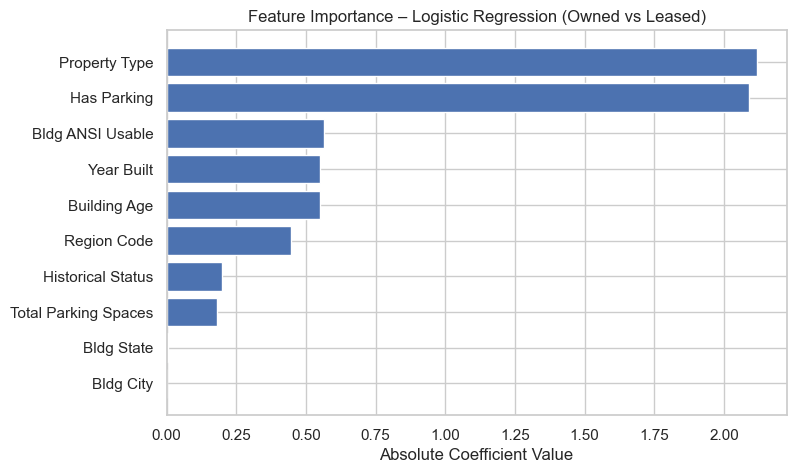

In [388]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

log_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': np.abs(log_reg.coef_[0])
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(log_importance['Feature'], log_importance['Importance'])
plt.title('Feature Importance – Logistic Regression (Owned vs Leased)')
plt.xlabel('Absolute Coefficient Value')
plt.gca().invert_yaxis()
plt.show()


#### The Logistic Regression model indicates that Building Age, Property Type, and Total Parking Spaces are the most influential predictors of ownership status. Buildings with greater age and larger infrastructure tend to be owned rather than leased.

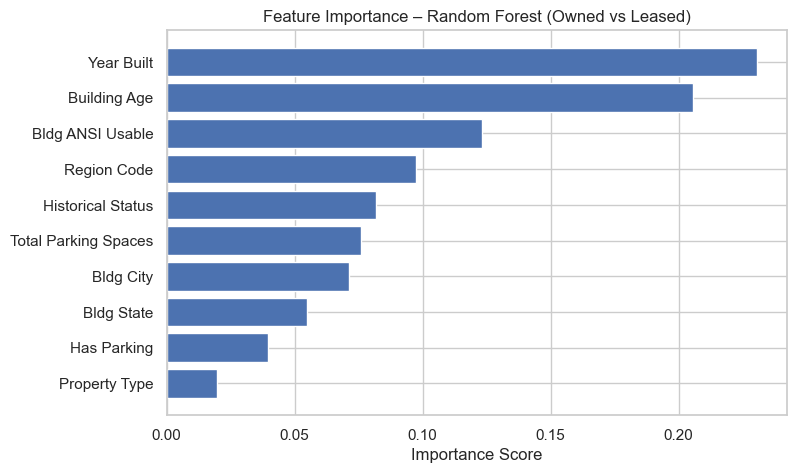

In [390]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(rf_importance['Feature'], rf_importance['Importance'])
plt.title('Feature Importance – Random Forest (Owned vs Leased)')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()


#### Random Forest results confirm that Building Age, Year Built, and Total Parking Spaces consistently contribute the most toward predicting ownership status, reinforcing findings across multiple models.

#### Classification 2: Historical Status

In [393]:
X = df_model[features].drop('Historical Status', axis=1)
y = df_model['Historical Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_hist = RandomForestClassifier()
rf_hist.fit(X_train, y_train)
y_pred = rf_hist.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.86441647597254


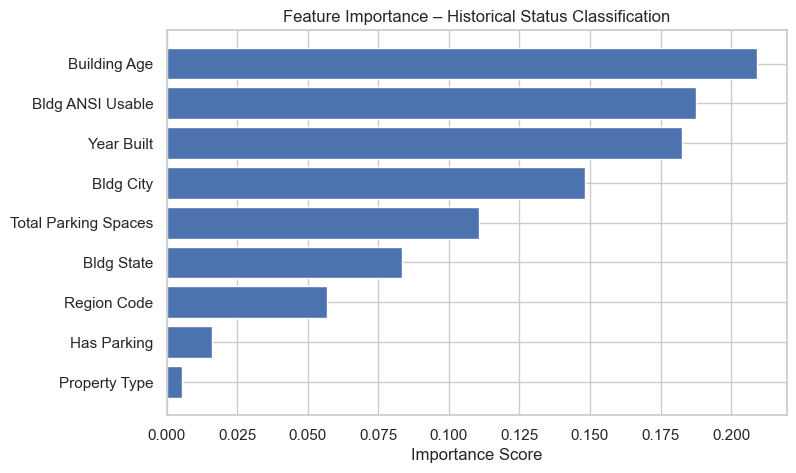

In [394]:
rf_hist = RandomForestClassifier(random_state=42)
rf_hist.fit(X_train, y_train)

hist_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_hist.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(hist_importance['Feature'], hist_importance['Importance'])
plt.title('Feature Importance – Historical Status Classification')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()


#### Feature importance analysis reveals that Year Built, Building Age, ANSI Usable, and Property Type are the most significant predictors of a building’s historical status. Older buildings with specific structural characteristics are more likely to be classified as historically significant

#### Classification 3: ABA Accessibility Compliance

In [397]:
X = df_model[features]
y = df_model['ABA Accessibility Flag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_aba = RandomForestClassifier()
rf_aba.fit(X_train, y_train)
y_pred = rf_aba.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.6573226544622426


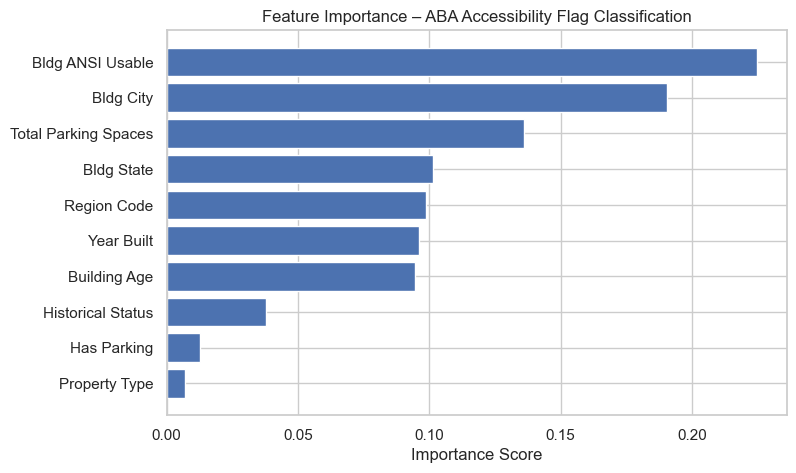

In [398]:
rf_hist = RandomForestClassifier(random_state=42)
rf_hist.fit(X_train, y_train)

hist_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_hist.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(hist_importance['Feature'], hist_importance['Importance'])
plt.title('Feature Importance – ABA Accessibility Flag Classification')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()


#### Analysis for ABA Accessibility Compliance shows that Building Age, ANSI Usable Area, Building City, and Total Parking Spaces are the most influential predictors. Older buildings are less likely to be compliant, as many were constructed before accessibility regulations were enforced. Larger buildings with higher ANSI usable area tend to support accessibility infrastructure more effectively. Parking availability is a key factor due to requirements for accessible parking spaces. The influence of building city reflects differences in local regulations and enforcement standards. Overall, accessibility compliance is driven by building age, size, infrastructure, and urban context.

#### Classification 4: Has Parking

In [401]:
X = df_model[features].drop('Has Parking', axis=1)
y = df_model['Has Parking']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt_parking = DecisionTreeClassifier()
dt_parking.fit(X_train, y_train)
y_pred = dt_parking.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


#### Regression 1: Building Age

In [403]:
X = df_model[features]
y = df_model['Building Age']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

reg_models = {
    'Linear': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Decision Tree': DecisionTreeRegressor()
}

reg_results = []

for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    reg_results.append([
        name,
        mean_absolute_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred, squared=False),
        r2_score(y_test, y_pred)
    ])

reg_results_df = pd.DataFrame(
    reg_results, columns=['Model', 'MAE', 'RMSE', 'R2']
)
reg_results_df


C:\Users\david\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\david\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\david\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\david\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the 

,Model,MAE,RMSE,R2
0,Linear,1.847736e-13,2.081584e-13,1.000000
1,Ridge,9.914067e-04,1.646029e-03,1.000000
2,Lasso,5.988003e-01,9.094268e-01,0.998070
3,Decision Tree,9.725400e-03,2.281655e-01,0.999879


#### Regression 2: Total Parking Spaces

In [405]:
X = df_model[features].drop('Total Parking Spaces', axis=1)
y = df_model['Total Parking Spaces']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))


R2 Score: -0.044174153269762595


#### The regression model for predicting total parking spaces yielded a low R² score, indicating weak explanatory power. This is primarily due to the highly skewed and zero-inflated nature of the target variable, as well as the absence of zoning and land-area features. To address this limitation, I decided to transform the target with log transform

In [407]:
X = df_model[features].drop('Total Parking Spaces', axis=1)
y = np.log1p(df_model['Total Parking Spaces'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))


R2 Score: 0.7811804869723843


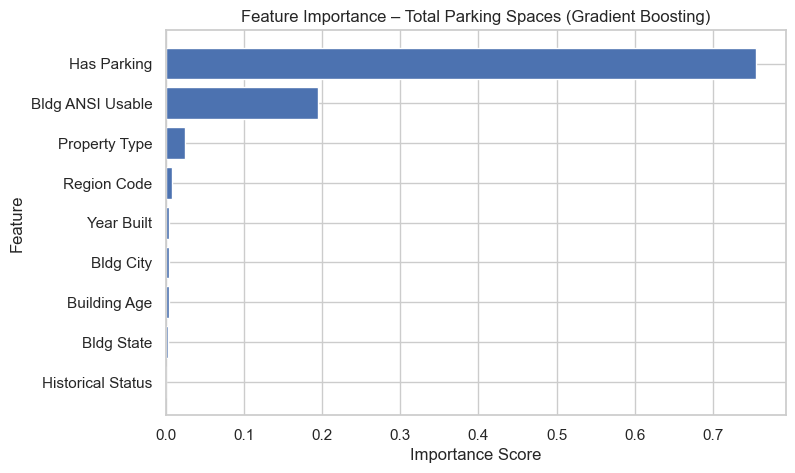

In [408]:
gb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(gb_importance['Feature'], gb_importance['Importance'])
plt.title('Feature Importance – Total Parking Spaces (Gradient Boosting)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()


#### Gradient Boosting effectively captures non-linear relationships and interactions, making it well-suited for predicting highly skewed infrastructure variables such as parking spaces. Analysis indicates that ANSI usable area, Has parking and Minor(Property type) are the strongest predictors of total parking availability reflecting the impact of urban planning and infrastructure density on parking capacity.

#### Regression 3: Year Built

In [411]:
X = df_model[features].drop('Year Built', axis=1)
y = df_model['Year Built']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_year = RandomForestRegressor()
rf_year.fit(X_train, y_train)
y_pred = rf_year.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))


R2 Score: 0.9999794144403565


#### Feature Importance for Construction Year Prediction to see determining factors

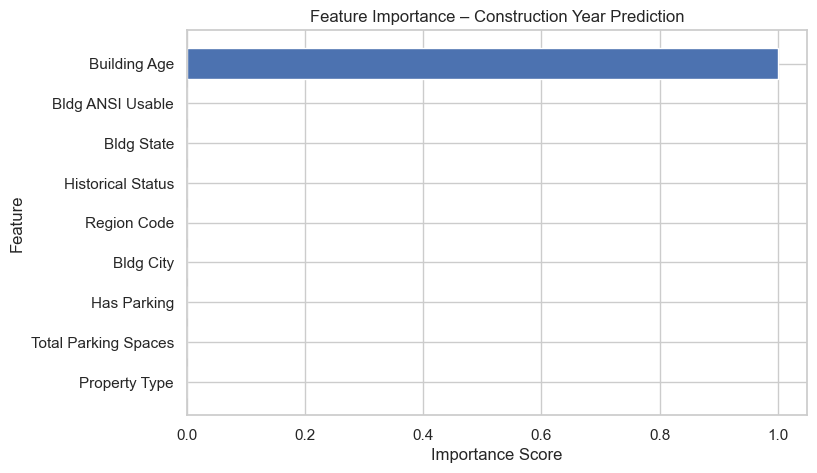

In [413]:
importances = rf_year.feature_importances_
features = X_train.columns

fi = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure()
plt.barh(fi['Feature'], fi['Importance'])
plt.title("Feature Importance – Construction Year Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.show()


#### Regression 4: Bldg ANSI Usable Area

In [415]:
X = df_model[features].drop('Bldg ANSI Usable', axis=1)
y = np.log1p(df_model['Bldg ANSI Usable'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_area = RandomForestRegressor()
rf_area.fit(X_train, y_train)
y_pred = rf_area.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.48025728791308875


#### This result suggests a moderate predictive relationship, where structural attributes such as building age, construction year, property type, and ownership status contribute meaningfully to estimating usable area. However, a substantial portion of the variance remains unexplained, likely due to the absence of key factors such as floor count, plot size, building design, and functional layout, which are not captured in the dataset. Overall, the model demonstrates reasonable performance for high-level infrastructure analysis but highlights the need for more detailed architectural and spatial variables to achieve stronger predictive accuracy.

#### Here I’m plotting a bar chart showing how many buildings each state has in the dataset. I’m using Seaborn’s styling for a clean look, sorting states by number of buildings, and rotating x-axis labels to keep it readable. It helps instantly spot which states have the most federal buildings.

C:\Users\david\AppData\Local\Temp\ipykernel_4204\3883315475.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=state_counts.index, y=state_counts.values, palette='viridis')


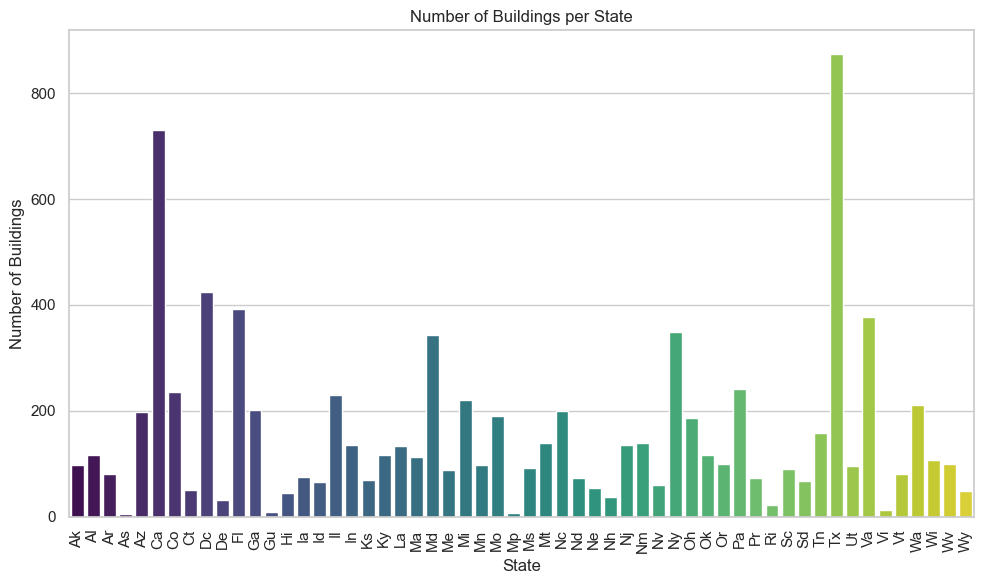

In [418]:
# plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Bar Chart: Buildings per State
state_counts = df['Bldg State'].value_counts().sort_values(ascending=False)
sns.barplot(x=state_counts.index, y=state_counts.values, palette='viridis')
plt.title("Number of Buildings per State")
plt.xlabel("State")
plt.ylabel("Number of Buildings")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


#### This chunk creates a pie chart comparing owned vs leased buildings. I’m using pastel colors for a soft visual and `autopct` to show exact percentages on the chart. It gives a quick sense of how government properties are managed—whether more are owned outright or leased.

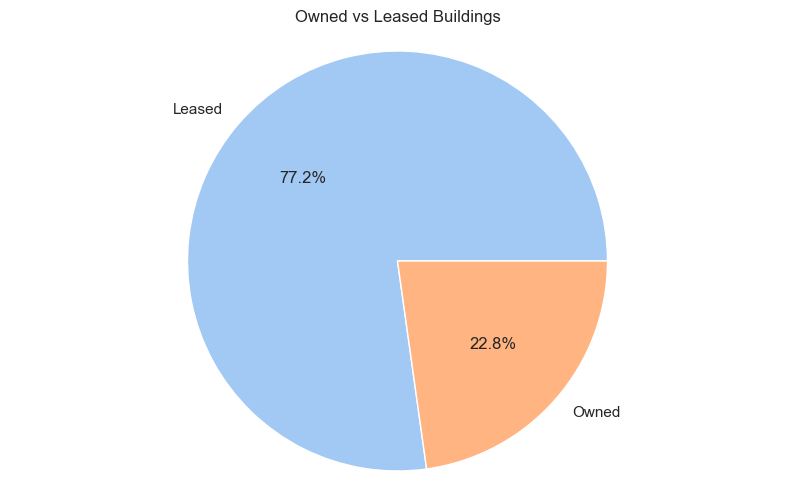

In [420]:
# Pie Chart: Owned vs Leased Buildings
ownership_counts = df['Owned/Leased'].value_counts()
plt.pie(ownership_counts, labels=ownership_counts.index, autopct='%1.1f%%', colors=sns.color_palette("pastel"))
plt.title("Owned vs Leased Buildings")
plt.axis('equal')
plt.show()


#### This heatmap shows ABA accessibility compliance rates across states. I used `crosstab` to count accessible vs non-accessible buildings per state, then normalized it to percentages for a fair comparison. The `YlGnBu` color palette highlights variations in compliance visually, making it easy to spot states doing well or lagging behind.

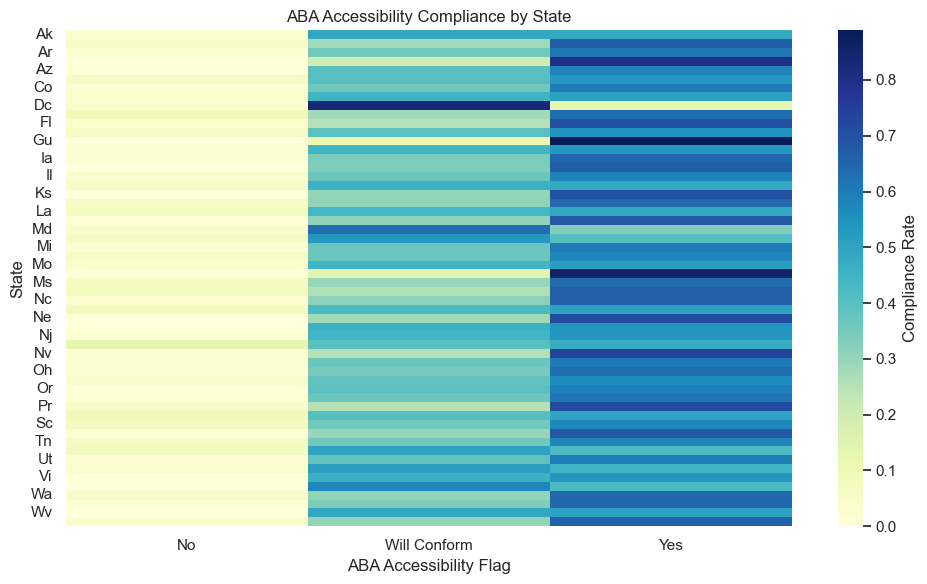

In [422]:
# Heatmap: ABA Compliance by State
aba_state = pd.crosstab(df['Bldg State'], df['ABA Accessibility Flag'])
aba_state_pct = aba_state.div(aba_state.sum(axis=1), axis=0)  # Convert to percentages
sns.heatmap(aba_state_pct, cmap="YlGnBu", annot=False, cbar_kws={'label': 'Compliance Rate'})
plt.title("ABA Accessibility Compliance by State")
plt.xlabel("ABA Accessibility Flag")
plt.ylabel("State")
plt.tight_layout()
plt.show()


#### This code calculates and visualizes the correlation matrix for the numeric columns in the dataset. It first selects the numeric columns using `select_dtypes(include='number')`, then computes the correlation using `corr()`. The resulting correlation matrix is displayed as a heatmap using Seaborn's `heatmap()` function. The heatmap helps identify relationships between numeric variables, where values closer to 1 or -1 indicate a strong positive or negative correlation, respectively.

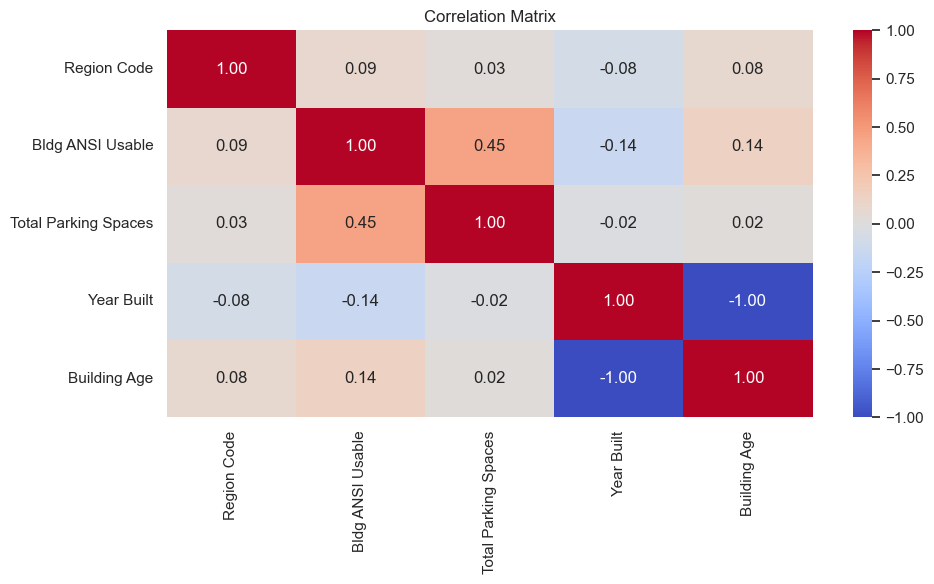

In [424]:
# Selecting only numeric columns for correlation
numeric_df = df.select_dtypes(include='number')

#Correlation Matrix and Heatmap: For numeric columns
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", cbar=True, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


#### Here I’m tagging buildings as **High Risk** if they’re older than 50 years, don’t have parking, *and* aren’t ABA compliant. I first make helper columns for each condition, combine them to flag risky buildings, then clean up by dropping the helpers. Finally, I plot how many fall under each risk level just to visualize the situation.

C:\Users\david\AppData\Local\Temp\ipykernel_4204\871269603.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='Set2')


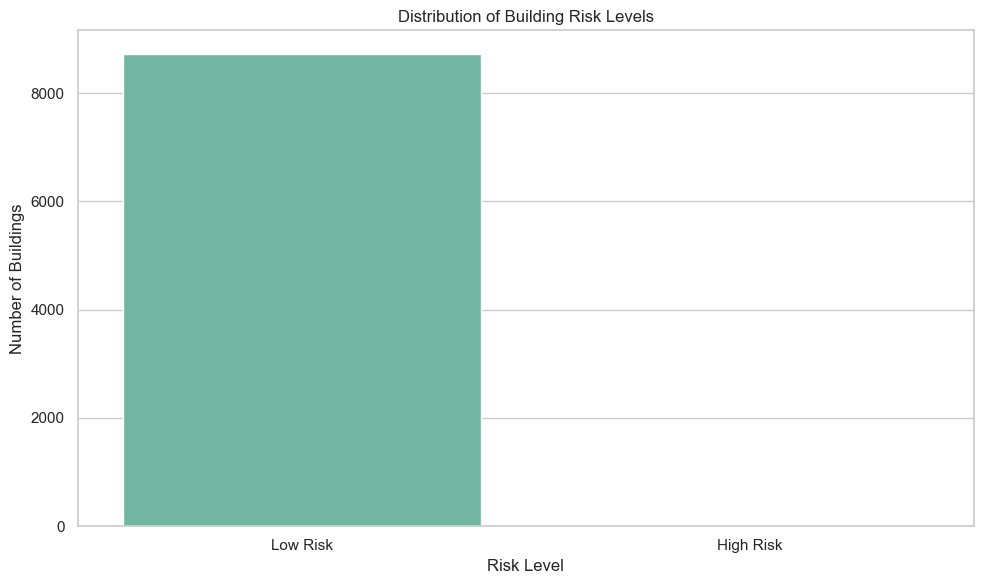

In [426]:
# Risk Column

# boolean columns for conditions
df['Old'] = df['Building Age'] > 50
df['No Parking'] = df['Has Parking'] == 'No'
df['Non-ABA'] = df['ABA Accessibility Flag'] == 'No'

# Combine into one 'Risk' column
df['Risk'] = df[['Old', 'No Parking', 'Non-ABA']].all(axis=1)
df['Risk'] = df['Risk'].map({True: 'High Risk', False: 'Low Risk'})

# Dropping helper columns
df.drop(['Old', 'No Parking', 'Non-ABA'], axis=1, inplace=True)

# Count of buildings by risk level
risk_counts = df['Risk'].value_counts()

sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='Set2')
plt.title("Distribution of Building Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Buildings")
plt.tight_layout()
plt.show()


#### Here, I’m creating a **Risk** column based on whether buildings are over 50 years old and not ABA compliant. I then plot the distribution of buildings across risk levels using both a bar chart and a pie chart. This gives a clear picture of how many buildings are considered **High Risk** versus **Low Risk**. The visualizations help identify the proportion and count of buildings at different risk levels.

C:\Users\david\AppData\Local\Temp\ipykernel_4204\1652783605.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='coolwarm')


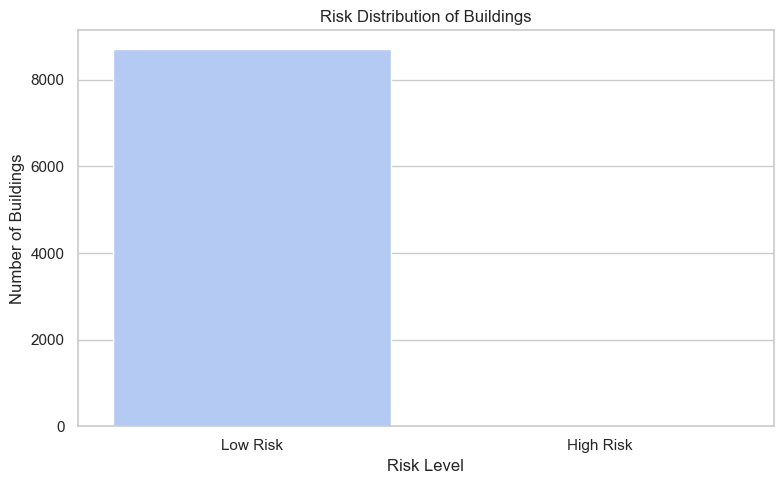

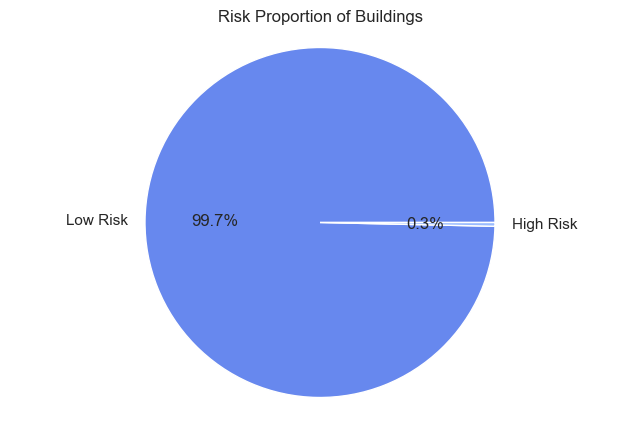

In [428]:
df['Old'] = df['Building Age'] > 50
df['Non-ABA'] = df['ABA Accessibility Flag'] == 'No'

# Combining only age and ABA flag into 'Risk' column
df['Risk'] = df[['Old', 'Non-ABA']].all(axis=1)
df['Risk'] = df['Risk'].map({True: 'High Risk', False: 'Low Risk'})

df.drop(['Old', 'Non-ABA'], axis=1, inplace=True)

# Set style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Bar Plot: Risk Distribution
risk_counts = df['Risk'].value_counts()
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='coolwarm')
plt.title("Risk Distribution of Buildings")
plt.xlabel("Risk Level")
plt.ylabel("Number of Buildings")
plt.tight_layout()
plt.show()

# Pie Chart: Risk Distribution
plt.pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', colors=sns.color_palette("coolwarm"))
plt.title("Risk Proportion of Buildings")
plt.axis('equal')
plt.show()


#### So finally, I’m checking out the "Historical Status" of the buildings. First, I count how many buildings fall into each status category and plot that in a bar chart. The x-axis shows the different status types, and the y-axis shows how many buildings fit each one. Then, just to dig a little deeper, I also look at how the historical status breaks down by state. I use a stacked bar chart for that, so each state shows the mix of different historical statuses. It's a good way to see how things are spread out across the states.

C:\Users\david\AppData\Local\Temp\ipykernel_4204\228802580.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=historical_status_counts.index, y=historical_status_counts.values, palette='viridis')


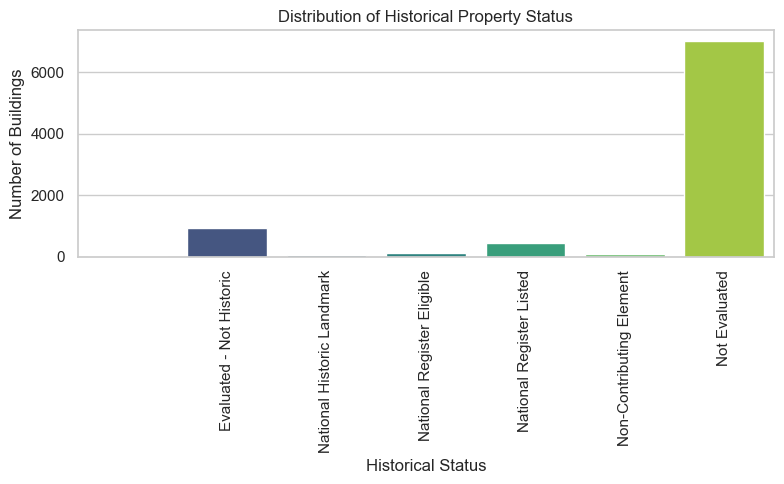

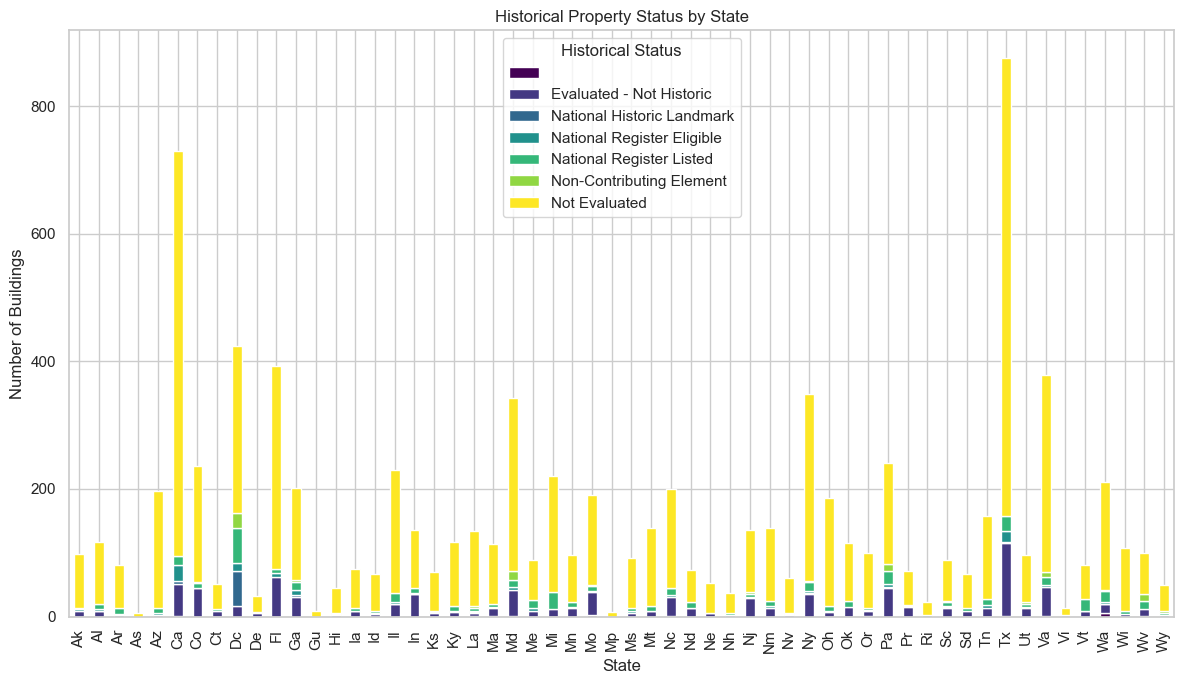

In [430]:
# Historical Status Analysis
historical_status_counts = df['Historical Status'].value_counts().sort_values(ascending=False)

# Visualizing the historical status distribution
sns.barplot(x=historical_status_counts.index, y=historical_status_counts.values, palette='viridis')
plt.title("Distribution of Historical Property Status")
plt.xlabel("Historical Status")
plt.ylabel("Number of Buildings")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Breakdown of Historical Status by State
historical_status_by_state = pd.crosstab(df['Bldg State'], df['Historical Status'])
historical_status_by_state.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='viridis')
plt.title("Historical Property Status by State")
plt.xlabel("State")
plt.ylabel("Number of Buildings")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
